# Data Preparation

The purpose of this notebook is to turn the recorded episodes into X and y for machine learning, and to split them into training, validation and test data.

In [1]:
# The notebook is not in the main folder of the project, so the imports need the working directory corrected.
import os

if "working_directory_corrected" not in vars():
    os.chdir("..")
    working_directory_corrected = True

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split

from data.episode import load_episode

## Target format

The models I want to try need one row of numbers per episode, but an episode is a table with a different number of frames each time. So every episode gets summarised:
- X: one row per episode with summary values of the joint positions
- y: 1 if the episode was successful, 0 if it failed

In [2]:
paths = sorted(Path("data/raw/place_perturbed_400/episodes").glob("*.npz"))
episodes = [load_episode(path) for path in paths]
len(episodes)

400

## X: features

From the exploration I know that only one arm works per episode. I take the 7 arm joints and 6 hand joints of that arm and compute mean, standard deviation, minimum, maximum and the last value of each. The episode length is added as one more feature.

`privileged.object_pose` is not used (and `load_episode` does not even load it).

In [3]:
def features(episode):
    if episode.arm == "left":
        arm = episode.state[:, 0:7]
        hand = episode.state[:, 14:20]
    else:
        arm = episode.state[:, 7:14]
        hand = episode.state[:, 20:26]
    joints = np.hstack([arm, hand])
    duration = episode.timestamp[-1]
    return np.concatenate(
        [[duration], joints.mean(axis=0), joints.std(axis=0), joints.min(axis=0), joints.max(axis=0), joints[-1]]
    )


joint_names = [
    "shoulder_pitch", "shoulder_roll", "shoulder_yaw", "elbow", "wrist_roll", "wrist_pitch", "wrist_yaw",
    "thumb_metacarpal", "thumb_proximal", "index", "middle", "ring", "pinky",
]
feature_names = ["duration"]
for stat in ["mean", "std", "min", "max", "last"]:
    for joint in joint_names:
        feature_names.append(f"{stat}_{joint}")

X = np.array([features(episode) for episode in episodes])
X.shape, len(feature_names)

((400, 66), 66)

## y: labels

In [4]:
y = np.array([int(episode.success) for episode in episodes])
print("successful:", (y == 1).sum(), "failed:", (y == 0).sum())

successful: 303 failed: 97


## Testing

Before using the data, check that nothing went wrong.

In [5]:
print("NaN values:", np.isnan(X).sum())
print("features that are the same in every episode:", [feature_names[i] for i in np.where(X.std(axis=0) == 0)[0]])

index = 3
print(episodes[index].name, "arm:", episodes[index].arm, "success:", y[index])
print("duration:", X[index, 0], "last timestamp:", episodes[index].timestamp[-1])
print("last_index:", X[index, feature_names.index("last_index")], "state[-1, 16]:", episodes[index].state[-1, 16])

NaN values: 0
features that are the same in every episode: []
episode_003 arm: left success: 0
duration: 10.500000000000343 last timestamp: 10.500000000000343
last_index: 0.00046140450285747647 state[-1, 16]: 0.00046140450285747647


episode_003 uses the left arm and column 16 is the left index finger, so the features are picked from the right columns.

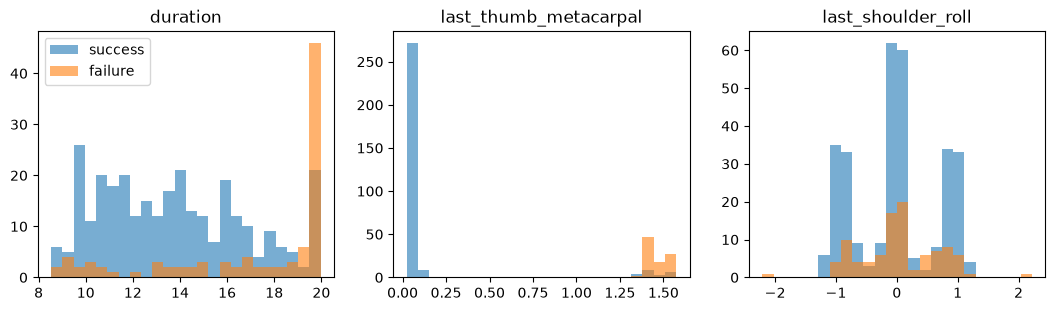

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, name in zip(axes, ["duration", "last_thumb_metacarpal", "last_shoulder_roll"]):
    column = X[:, feature_names.index(name)]
    bins = np.linspace(column.min(), column.max(), 25)
    ax.hist(column[y == 1], bins=bins, alpha=0.6, label="success")
    ax.hist(column[y == 0], bins=bins, alpha=0.6, label="failure")
    ax.set_title(name)
axes[0].legend()
plt.show()

Two things to remember from these plots:

- `last_thumb_metacarpal` separates the classes very well. In almost all failed episodes the thumb is still at 1.4 at the end, in most successful ones it is back near 0. This fits what I saw in the exploration.
- `last_shoulder_roll` has three groups that have nothing to do with success. The outer two are the arms: the value is positive in left-arm episodes and negative in right-arm episodes, because the two arms are mirrored. So the same pose can have the opposite sign depending on the arm. I leave it like that for now.

## Split

20 % of the episodes are put aside as test set and not touched until the final evaluation. The rest is split again into training and validation data. Both splits are stratified so that every part has the same share of failures.

In [7]:
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
X_train, X_val, y_train, y_val = train_test_split(X_rest, y_rest, test_size=0.25, stratify=y_rest, random_state=0)

for name, part in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{name:10s} n={len(part):3d}  failures={(part == 0).sum():2d}  success rate={part.mean():.2f}")

train      n=240  failures=58  success rate=0.76
validation n= 80  failures=20  success rate=0.75
test       n= 80  failures=19  success rate=0.76


## Conclusions

The data is ready: 400 rows with 66 features, no missing values, and a 240 / 80 / 80 split with the same success rate in every part.

The feature function and the split only live in this notebook at the moment. The model selection notebook needs them too.